# Bank Marketing — Dashboard: What drives term-deposit subscription?

## 0. Setup

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from scipy.stats import chi2_contingency

sns.set_theme(style="whitegrid")

DATA_PATH = "../dataset/bank/bank-full.csv"
FIG_DIR = Path("figures")
FIG_DIR.mkdir(exist_ok=True)

HIGH, LOW = "#2a9d8f", "#c0c0c0"  # above / below overall rate


def save_fig(name):
    plt.savefig(FIG_DIR / f"{name}.png", dpi=200, bbox_inches="tight")

## 1. Data

In [2]:
df_raw = pd.read_csv(DATA_PATH, sep=";")

In [3]:
COLUMN_MAP = {
    "default": "has_credit_default",           # has credit in default? (yes/no)
    "balance": "avg_yearly_balance",           # average yearly balance (euros)
    "housing": "has_housing_loan",             # has housing loan? (yes/no)
    "loan": "has_personal_loan",               # has personal loan? (yes/no)
    "contact": "contact_type",                 # contact communication type: cellular / telephone / unknown
    "day": "last_contact_day",                 # last contact day of month
    "month": "last_contact_month",             # last contact month of year
    "duration": "last_contact_duration",       # last contact duration (seconds); leakage, benchmark only
    "campaign": "n_contacts_this_campaign",    # contacts during this campaign (incl. last contact)
    "pdays": "days_since_prev_campaign",       # days since last contact in a previous campaign (-1 = never)
    "previous": "n_contacts_before_campaign",  # contacts before this campaign
    "poutcome": "prev_campaign_outcome",       # outcome of the previous campaign
    "y": "subscribed_term_deposit",            # target: has the client subscribed a term deposit?
}

df = df_raw.rename(columns=COLUMN_MAP)

In [4]:
YES_NO_COLS = ["has_credit_default", "has_housing_loan", "has_personal_loan", "subscribed_term_deposit"]

for col in YES_NO_COLS:
    df[col] = df[col].map({"yes": 1, "no": 0})

In [5]:
TARGET = "subscribed_term_deposit"
MONTH_ORDER = ["jan", "feb", "mar", "apr", "may", "jun", "jul", "aug", "sep", "oct", "nov", "dec"]

# grouped versions of numerical factors
df["age_group"] = pd.cut(df["age"], [17, 30, 40, 50, 60, 95], labels=["18-30", "31-40", "41-50", "51-60", "61+"])
df["balance_group"] = pd.qcut(df["avg_yearly_balance"], 5, labels=["Q1 (lowest)", "Q2", "Q3", "Q4", "Q5 (highest)"])
df["calls_group"] = pd.cut(df["n_contacts_this_campaign"], [0, 1, 2, 3, 5, 10, 63], labels=["1", "2", "3", "4-5", "6-10", "11+"])
df["was_contacted_before"] = (df["days_since_prev_campaign"] != -1).astype(int)

OVERALL = df[TARGET].mean()
OVERALL

np.float64(0.11698480458295547)

## 2. Factor ranking

In [6]:
# last_contact_duration excluded: known only after the call (leakage)
FACTORS = {
    "Client": ["age_group", "job", "marital", "education", "balance_group",
               "has_credit_default", "has_housing_loan", "has_personal_loan"],
    "Campaign": ["last_contact_month", "contact_type", "calls_group",
                 "was_contacted_before", "prev_campaign_outcome"],
}


def cramers_v(col):
    table = pd.crosstab(df[col], df[TARGET])
    chi2 = chi2_contingency(table)[0]
    return np.sqrt(chi2 / (len(df) * (min(table.shape) - 1)))


ranking = pd.DataFrame(
    [{"factor": col, "group": group, "cramers_v": cramers_v(col)} for group, cols in FACTORS.items() for col in cols]
).sort_values("cramers_v")
ranking

,factor,group,cramers_v
5,has_credit_default,Client,0.022160
2,marital,Client,0.065926
7,has_personal_loan,Client,0.068091
3,education,Client,0.072695
10,calls_group,Campaign,0.087635
4,balance_group,Client,0.098685
1,job,Client,0.135990
6,has_housing_loan,Client,0.139103
9,contact_type,Campaign,0.151355
11,was_contacted_before,Campaign,0.167174


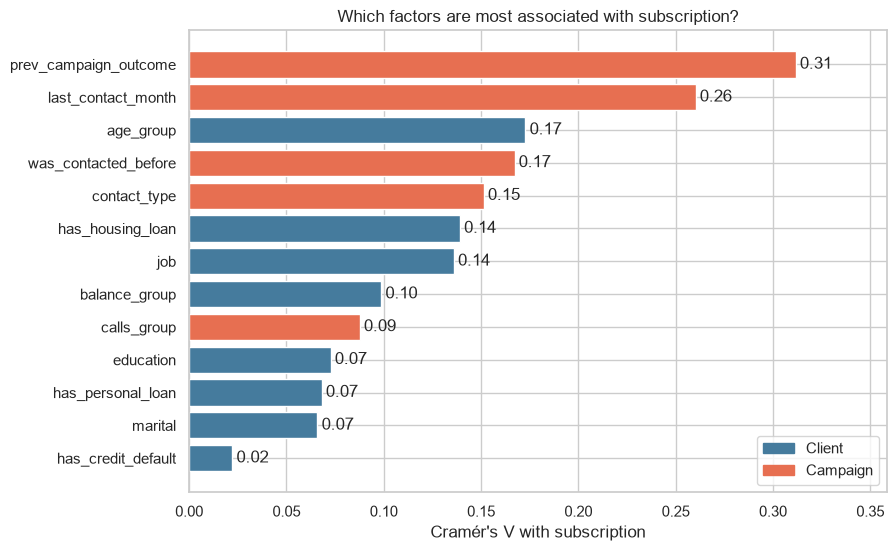

In [7]:
fig, ax = plt.subplots(figsize=(9, 6))
colors = ranking["group"].map({"Client": "#457b9d", "Campaign": "#e76f51"})
bars = ax.barh(ranking["factor"], ranking["cramers_v"], color=colors)
ax.bar_label(bars, fmt="%.2f", padding=3)
ax.set_xlim(0, ranking["cramers_v"].max() * 1.15)
ax.set_xlabel("Cramér's V with subscription")
ax.set_title("Which factors are most associated with subscription?")
ax.legend(handles=[plt.Rectangle((0, 0), 1, 1, color=c) for c in ["#457b9d", "#e76f51"]], labels=["Client", "Campaign"])
save_fig("dashboard_1_factor_ranking")
plt.show()

## 3. Subscription rate by factor

In [8]:
def plot_rate(ax, col, order=None):
    rate = df.groupby(col, observed=True)[TARGET].agg(["mean", "size"])
    rate = rate.reindex(order) if order else rate.sort_values("mean")
    bars = ax.barh(rate.index.astype(str), rate["mean"], color=[HIGH if m > OVERALL else LOW for m in rate["mean"]])
    ax.bar_label(bars, labels=[f"{m:.1%} (n={n:,})" for m, n in zip(rate["mean"], rate["size"])], padding=3, fontsize=9)
    ax.axvline(OVERALL, color="red", linestyle="--")
    ax.set_xlim(0, rate["mean"].max() * 1.45)
    ax.xaxis.set_major_formatter(plt.matplotlib.ticker.PercentFormatter(1.0))
    if order:
        ax.invert_yaxis()  # first category on top
    ax.set_title(col)
    ax.set_ylabel("")

### 3.1 Client factors

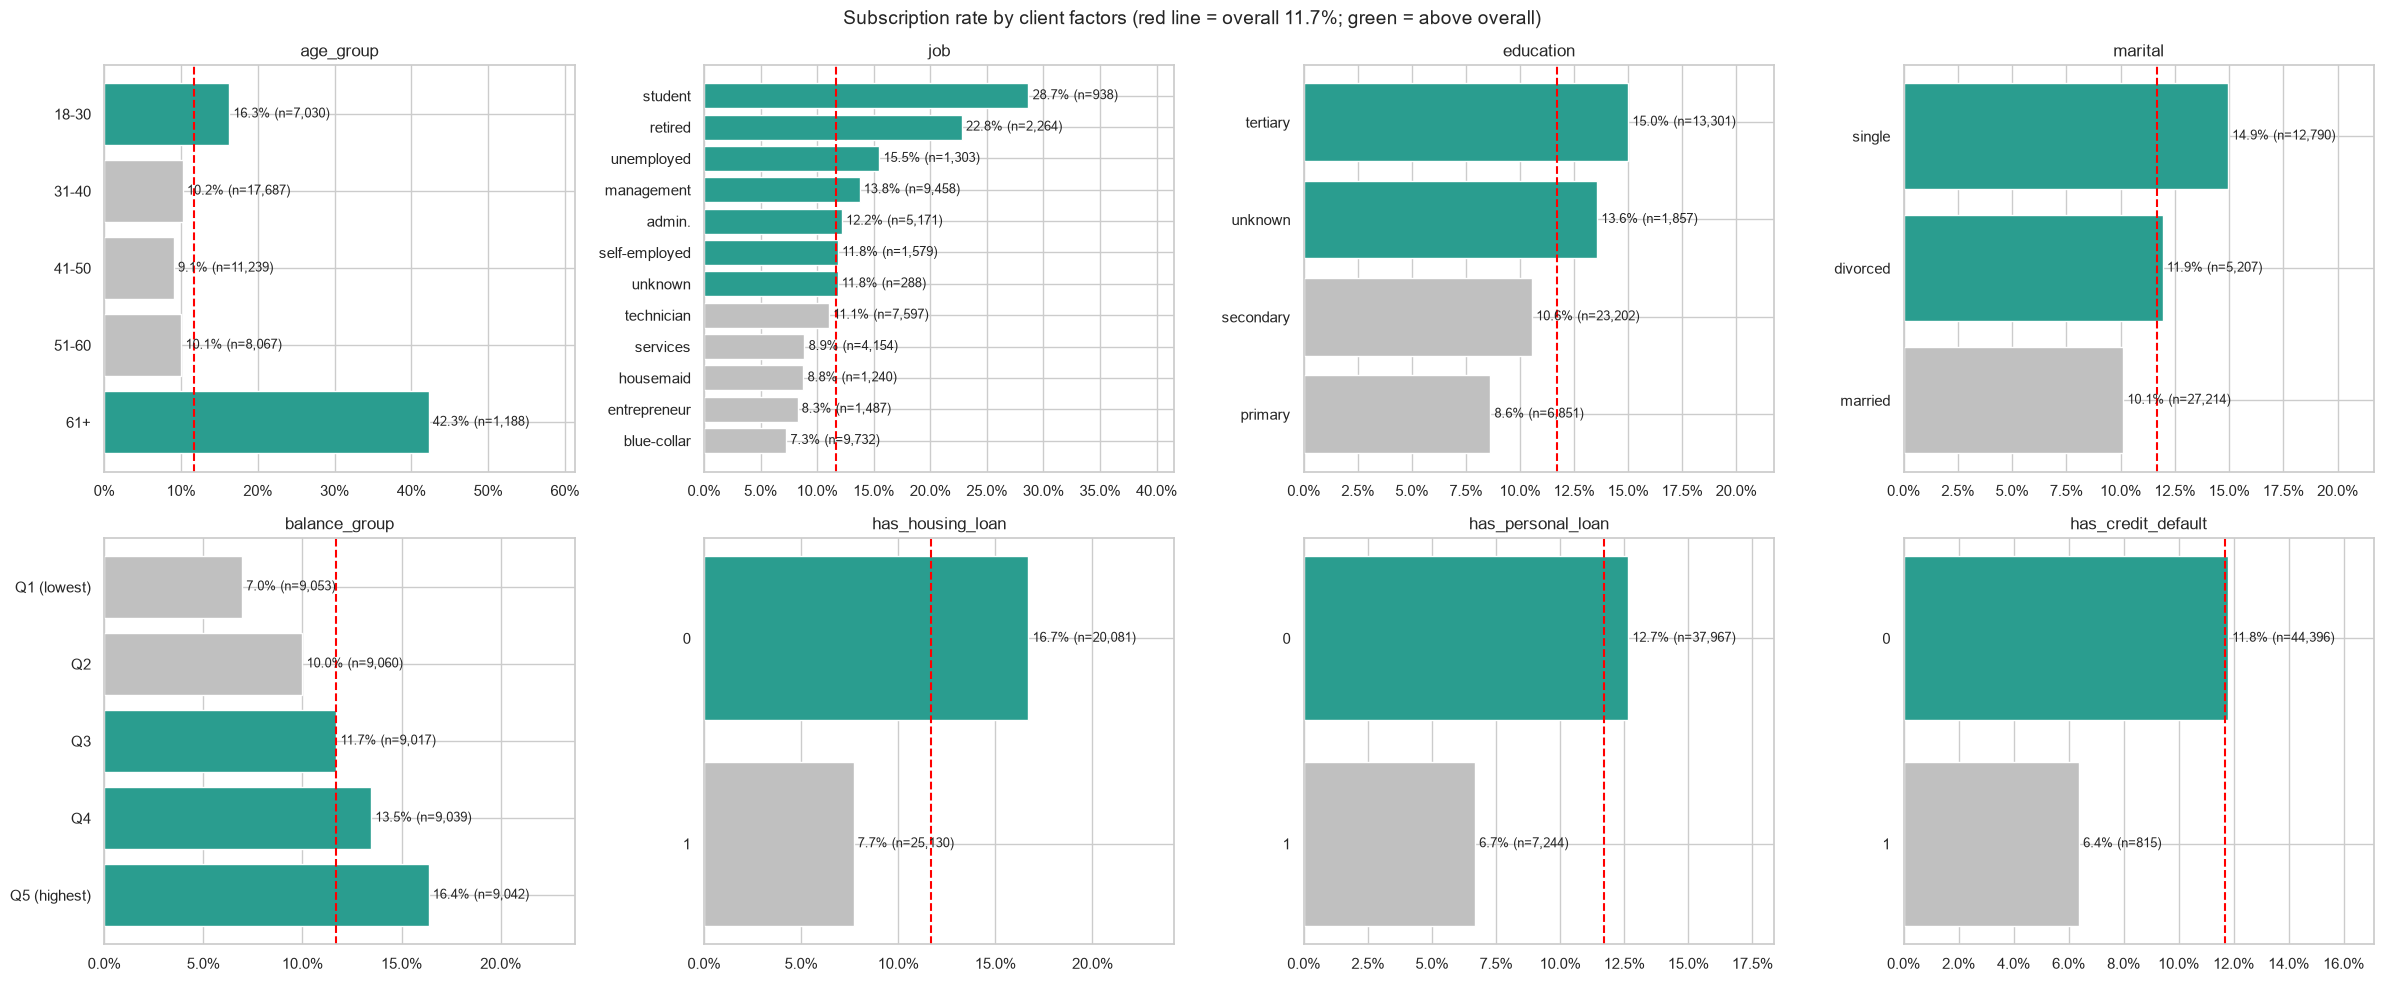

In [9]:
fig, axes = plt.subplots(2, 4, figsize=(24, 10))
plot_rate(axes[0, 0], "age_group", order=list(df["age_group"].cat.categories))
plot_rate(axes[0, 1], "job")
plot_rate(axes[0, 2], "education")
plot_rate(axes[0, 3], "marital")
plot_rate(axes[1, 0], "balance_group", order=list(df["balance_group"].cat.categories))
plot_rate(axes[1, 1], "has_housing_loan", order=[0, 1])
plot_rate(axes[1, 2], "has_personal_loan", order=[0, 1])
plot_rate(axes[1, 3], "has_credit_default", order=[0, 1])
fig.suptitle(f"Subscription rate by client factors (red line = overall {OVERALL:.1%}; green = above overall)", fontsize=14)
plt.tight_layout()
save_fig("dashboard_2_client_factors")
plt.show()

### 3.2 Campaign factors

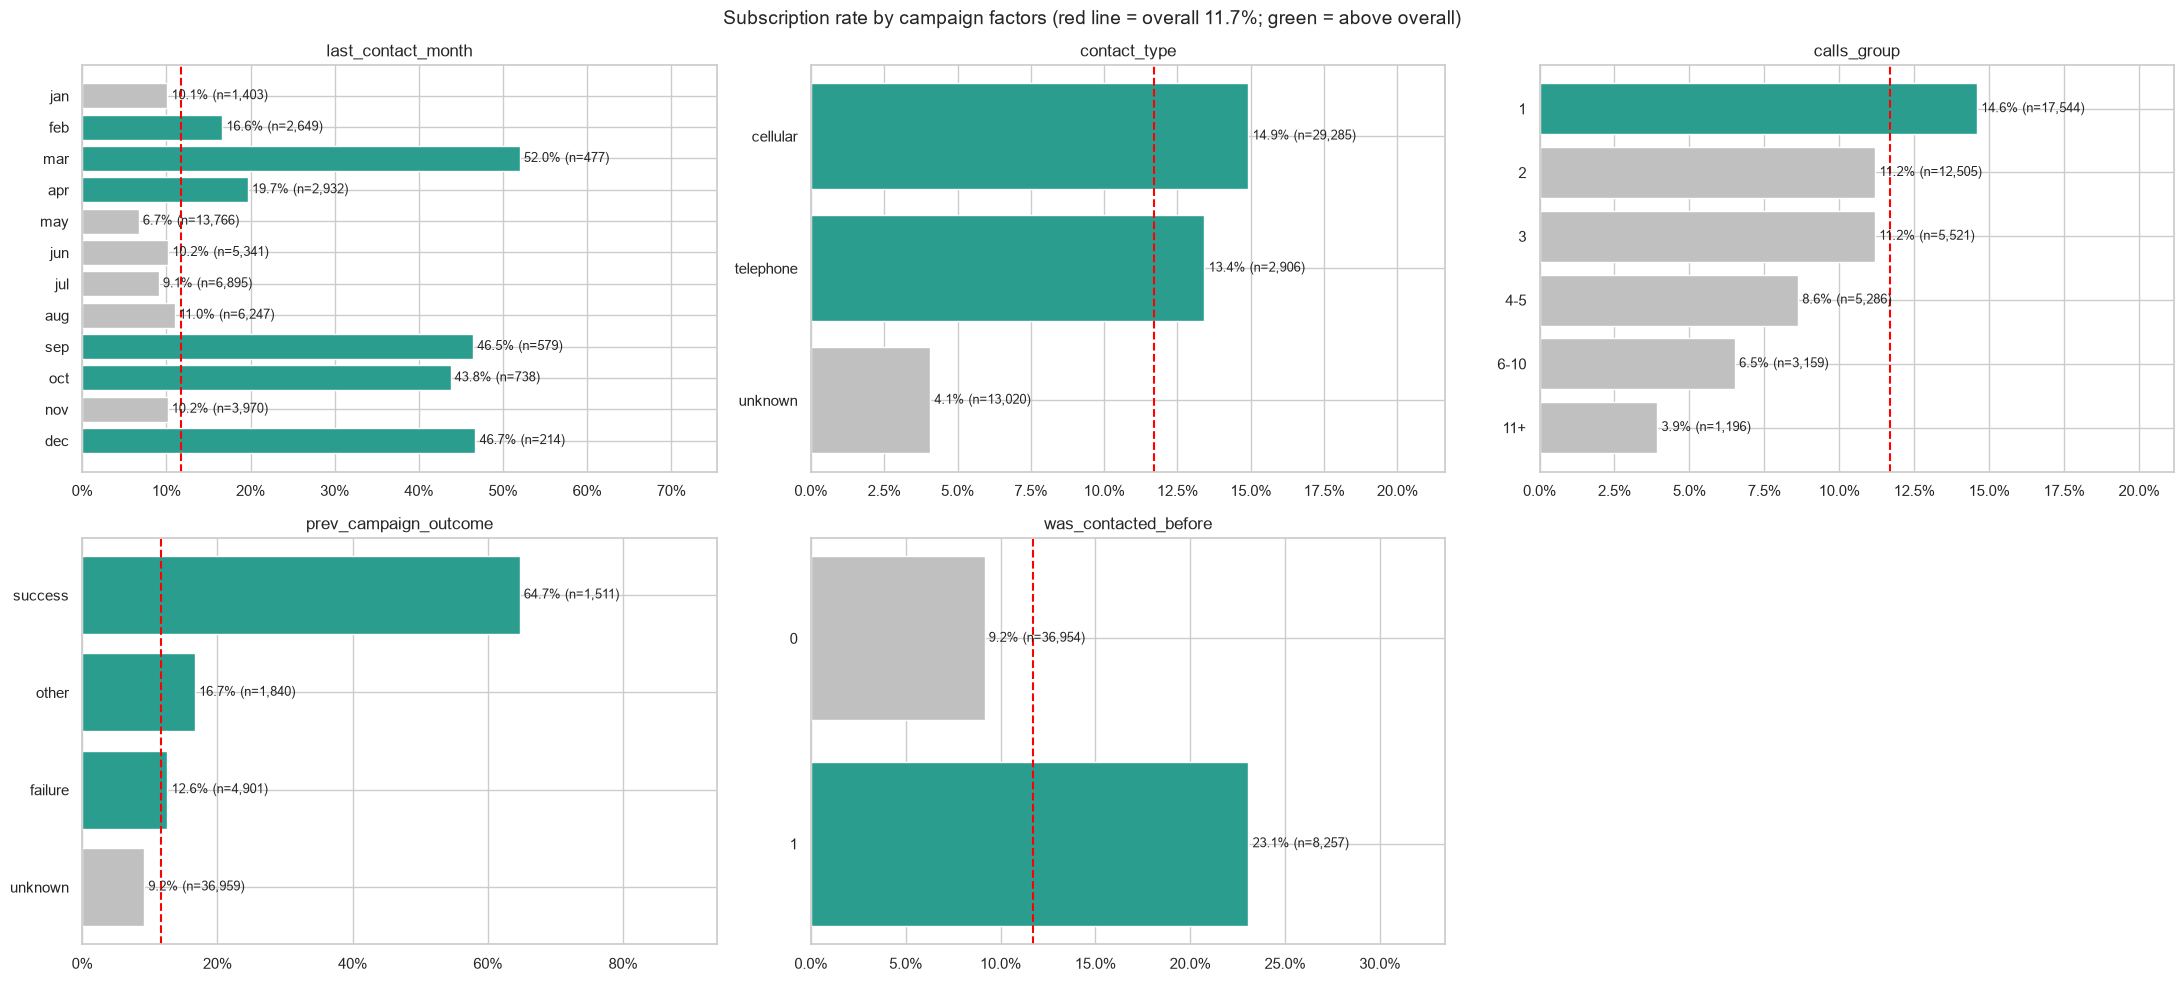

In [10]:
fig, axes = plt.subplots(2, 3, figsize=(22, 10))
plot_rate(axes[0, 0], "last_contact_month", order=MONTH_ORDER)
plot_rate(axes[0, 1], "contact_type")
plot_rate(axes[0, 2], "calls_group", order=list(df["calls_group"].cat.categories))
plot_rate(axes[1, 0], "prev_campaign_outcome")
plot_rate(axes[1, 1], "was_contacted_before", order=[0, 1])
axes[1, 2].axis("off")
fig.suptitle(f"Subscription rate by campaign factors (red line = overall {OVERALL:.1%}; green = above overall)", fontsize=14)
plt.tight_layout()
save_fig("dashboard_3_campaign_factors")
plt.show()

## 4. Key segments

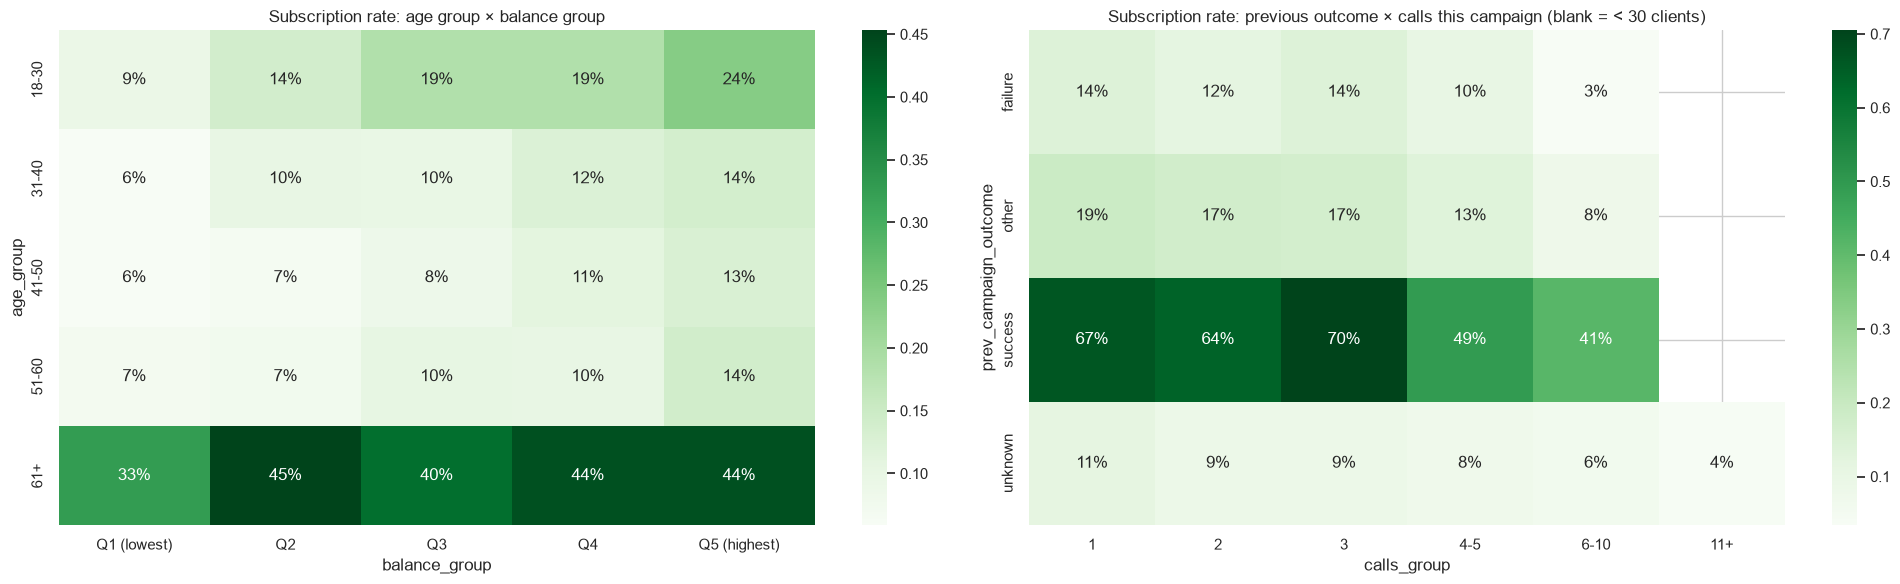

In [11]:
def segment_rate(rows, cols):
    rate = df.pivot_table(index=rows, columns=cols, values=TARGET, aggfunc="mean", observed=True)
    size = df.pivot_table(index=rows, columns=cols, values=TARGET, aggfunc="size", observed=True)
    return rate.where(size >= 30)  # hide cells with < 30 clients


fig, axes = plt.subplots(1, 2, figsize=(20, 6))
sns.heatmap(segment_rate("age_group", "balance_group"), annot=True, fmt=".0%", cmap="Greens", ax=axes[0])
axes[0].set_title("Subscription rate: age group × balance group")
sns.heatmap(segment_rate("prev_campaign_outcome", "calls_group"), annot=True, fmt=".0%", cmap="Greens", ax=axes[1])
axes[1].set_title("Subscription rate: previous outcome × calls this campaign (blank = < 30 clients)")
plt.tight_layout()
save_fig("dashboard_4_key_segments")
plt.show()